# Interference -- Ideal Double Slit

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
d1 = 250              # slit separation in microns


# --- Data Generation ---
# Generate x values from -10^5 to 10^5
numpointsx1 = 512
x1 = np.linspace(-1e5,1e5,num=numpointsx1)
intensity1 = (np.cos(np.pi*d1/wavelength1*x1/np.sqrt(x1**2+L1**2)))**2


## Plot

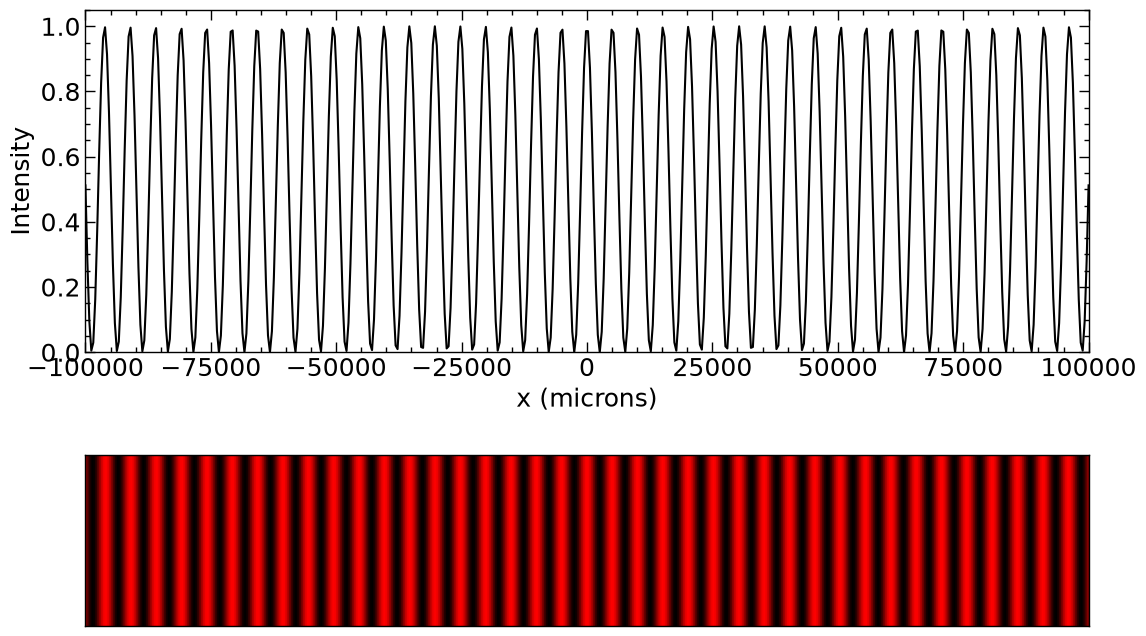

In [4]:
fig1, (ax1, ax2) = plt.subplots(2, 1, figsize=(8*1.618,8), gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.4})

# 1. Line Plot
ax1.plot(x1, intensity1, color='k', linewidth=1.5)
ax1.set_xlim(-10**5, 10**5)
ax1.set_ylim(0, 1.05)
ax1.set_xlabel("x (microns)")
ax1.set_ylabel("Intensity")
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# 2. Density Plot (Simulating the visual pattern)
# Create a custom Black-to-Green colormap to match RGBColor[0, #, 0]
colors = [(0, 0, 0), (1, 0, 0)] # Black to Red
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)

# Expand the 1D intensity array into 2D for image plotting
# We tile it vertically to give it height
intensity1_2d = np.tile(intensity1, (100, 1))

# Plot using imshow
# aspect='auto' allows the plot to stretch to fill the figure width
# extent sets the axis labels to match the real coordinates
ax2.imshow(intensity1_2d, extent=[-10**5, 10**5, -1, 1], 
           aspect='auto', cmap=laser_cmap, vmin=0, vmax=1)

ax2.set_xticks([]) # Remove x ticks for the density plot
ax2.set_yticks([]) # Remove y ticks as they are arbitrary
ax2.tick_params(direction='in')

plt.show()

# Animation

In [5]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import ipywidgets as widgets
from IPython.display import display

# --- 1. Global Setup & Styling ---
plot_params2 = {
    'font.size': 12, # Slightly smaller for interactive view
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
}
plt.rcParams.update(plot_params2)

# Constants
L2 = 2 * 10**6      # Distance to screen (microns)
X_RANGE = 1e5       # Plot range (microns)
NUM_POINTS = 512    # Resolution

# Data Arrays (Global x axis)
x2 = np.linspace(-X_RANGE, X_RANGE, num=NUM_POINTS)

# --- 2. Helper: Wavelength to RGB ---
def wavelength_to_rgb(wavelength, gamma=0.8):
    '''This converts a given wavelength of light to an 
    approximate RGB color value. The wavelength must be given
    in nanometers in the range from 380 nm through 750 nm.'''
    wavelength = float(wavelength)
    if wavelength >= 380 and wavelength <= 440:
        attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
        R = (-(wavelength - 440) / (440 - 380)) * attenuation
        G = 0.0
        B = 1.0 * attenuation
    elif wavelength >= 440 and wavelength <= 490:
        R = 0.0
        G = (wavelength - 440) / (490 - 440)
        B = 1.0
    elif wavelength >= 490 and wavelength <= 510:
        R = 0.0
        G = 1.0
        B = -(wavelength - 510) / (510 - 490)
    elif wavelength >= 510 and wavelength <= 580:
        R = (wavelength - 510) / (580 - 510)
        G = 1.0
        B = 0.0
    elif wavelength >= 580 and wavelength <= 645:
        R = 1.0
        G = -(wavelength - 645) / (645 - 580)
        B = 0.0
    elif wavelength >= 645 and wavelength <= 750:
        attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
        R = 1.0 * attenuation
        G = 0.0
        B = 0.0 * attenuation
    else:
        R = 0.0; G = 0.0; B = 0.0
    return (R, G, B)

# --- 3. Figure Initialization ---
# Create figure
fig, (ax3, ax4) = plt.subplots(2, 1, figsize=(9, 6), 
                               gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.3})

# Remove the default "Figure 1" header from ipympl output
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

# Initial Parameters
init_d = 250.0
init_w = 0.632 # microns

# Calculate Initial Data
intensity = (np.cos(np.pi * init_d / init_w * x2 / np.sqrt(x2**2 + L2**2)))**2
intensity_2d = np.tile(intensity, (100, 1))
init_color = wavelength_to_rgb(init_w * 1000)

# --- Plot Artists (Stored in variables for fast updates) ---
# 1. Line Plot
line_plot, = ax3.plot(x2, intensity, color=init_color, linewidth=2)
ax3.set_xlim(-X_RANGE, X_RANGE)
ax3.set_ylim(0, 1.05)
ax3.set_ylabel("Intensity")
ax3.minorticks_on()
ax3.tick_params(which='both', direction="in", width=1, top=True, right=True)

# 2. Density Plot
# Initialize with a dynamic colormap based on wavelength
laser_cmap2 = LinearSegmentedColormap.from_list("laser", [(0,0,0), init_color])
img_plot = ax4.imshow(intensity_2d, extent=[-X_RANGE, X_RANGE, -1, 1], 
                      aspect='auto', cmap=laser_cmap2, vmin=0, vmax=1)
ax4.set_xlabel("x (microns)")
ax4.set_yticks([])
ax4.tick_params(direction='in')

plt.tight_layout()

# --- 4. The Core Logic (Separated for Movie Saving) ---
def update_simulation(d_val, w_val):
    """
    Calculates physics and updates plot artists.
    d_val: slit separation in microns
    w_val: wavelength in microns
    """
    # 1. Math (Vectorized, On-the-fly)
    # factor = pi * d / (lambda * L_effective)
    # Using small angle approx L_eff ~ L2 for speed if desired, 
    # but keeping full sqrt calculation as requested, it is fast enough.
    k_factor = (np.pi * d_val) / (w_val * np.sqrt(x2**2 + L2**2))
    new_intensity = np.cos(k_factor * x2)**2
    
    # 2. Update Line
    line_plot.set_ydata(new_intensity)
    
    # 3. Update Image
    # Tile 1D array to 2D
    new_intensity_2d = np.tile(new_intensity, (100, 1))
    img_plot.set_data(new_intensity_2d)
    
    # 4. Update Colors (Visual Candy)
    rgb = wavelength_to_rgb(w_val * 1000) # Convert um to nm for color func
    line_plot.set_color(rgb)
    
    # Update colormap efficiently
    new_cmap = LinearSegmentedColormap.from_list("laser", [(0,0,0), rgb])
    img_plot.set_cmap(new_cmap)
    
    fig.canvas.draw_idle()

# --- 5. Interactive Widget Wrappers ---
def on_change(change):
    update_simulation(d_slider.value, w_slider.value)

# Sliders
d_slider = widgets.FloatSlider(value=250, min=50, max=500, step=1, description='Separation (d)')
w_slider = widgets.FloatSlider(value=0.632, min=0.400, max=0.700, step=0.001, description='Wavelength (um)')

d_slider.observe(on_change, names='value')
w_slider.observe(on_change, names='value')

# Display
display(widgets.VBox([d_slider, w_slider]))

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-01_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-01.html) (direct link: [ch04-01_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-01_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.